In [1]:
from collections import defaultdict
from pathlib import Path

import pandas as pd
from acteval.plot.frequency import plot_agg_acts
from matplotlib import pyplot as plt
from matplotlib.patches import Patch

In [2]:
cmap = {
    "home": (0.5529411764705883, 0.8274509803921568, 0.7803921568627451),
    "other": (1.0, 1.0, 0.7019607843137254),
    "shop": (0.7450980392156863, 0.7294117647058823, 0.8549019607843137),
    "work": (0.984313725490196, 0.5019607843137255, 0.4470588235294118),
    "escort": (0.5019607843137255, 0.6941176470588235, 0.8274509803921568),
    "visit": (0.9921568627450981, 0.7058823529411765, 0.3843137254901961),
    "education": (0.7019607843137254, 0.8705882352941177, 0.4117647058823529),
    "medical": (0.9882352941176471, 0.803921568627451, 0.8980392156862745),
    "travel": (0.8509803921568627, 0.8509803921568627, 0.8509803921568627),
    "leisure": (0.996078431372549, 0.8509803921568627, 0.6509803921568628),
}


def latest(path: Path):
    versions = sorted(
        [
            d
            for d in path.iterdir()
            if d.is_dir() and d.name.startswith("version")
        ]
    )
    print(
        f"Found versions for {path.name}: {[v.name for v in versions]}. Returning {versions[-1]}"
    )
    return path.name, versions[-1]


def earliest(path: Path):
    versions = sorted(
        [
            d
            for d in path.iterdir()
            if d.is_dir() and d.name.startswith("version")
        ]
    )
    print(
        f"Found versions for {path.name}: {[v.name for v in versions]}. Returning {versions[-1]}"
    )
    return path.name, versions[0]


def iter_models(path: Path):
    for dir in path.iterdir():

        if dir.is_dir():

            yield latest(dir)


def find_nth(path: Path, n=0):

    ranks = (
        pd.read_csv(path / "domain_distances.csv")
        .drop(columns=["domain", "observed", "mean", "std"], errors="ignore")
        .rank(axis=1, method="min")
        .sum(axis=0)
    )
    ranked = [i for _, i in sorted(zip(ranks, ranks.index))]
    top = ranked[n]
    dir = path / top
    yield latest(dir)


def best_quality(path: Path, n=0):

    data = pd.read_csv(path / "domain_distances.csv")
    data = data[data.domain == "sample quality"].drop(
        columns=["domain", "observed", "mean", "std"], errors="ignore"
    )
    ranks = data.rank(axis=1, method="min").sum(axis=0)
    ranked = [i for _, i in sorted(zip(ranks, ranks.index))]
    top = ranked[n]
    dir = path / top
    yield latest(dir)


def load_attributes(path: Path, default=None):
    if (path / "synthetic_attributes.csv").exists():
        print(f"Loading synthetic attributes from {path}")
        return pd.read_csv(path / "synthetic_attributes.csv")
    if (path / "synthetic_labels.csv").exists():
        print(f"Loading synthetic labels from {path}")
        return pd.read_csv(path / "synthetic_labels.csv")
    print(f"Failed to find attributes at {path}")
    return default


def split_on(schedules, attributes, by="work_status"):
    splits = attributes.groupby(by)
    return {
        k: schedules.loc[schedules.pid.isin(list(v.pid))]
        for k, v in splits
        if k != "unknown"
    }


def styler(df, vmin=-1, vmax=1):
    df = -df
    df.loc["24", "london"] = None
    df.loc["00-24", "london"] = None
    for yrs in ["24"]:
        for source in ["west", "global"]:
            df.loc[yrs, source] = None

    styled = df.style.background_gradient(
        cmap="RdYlGn", vmin=vmin, vmax=vmax
    ).format("{:.1%}", na_rep="")

    return styled

In [ ]:
training_data_route = Path("../../tmp/foundation/extrapolate")

target_schedules = pd.read_csv(training_data_route / "base_activities.csv")
target_attributes = pd.read_csv(training_data_route / "base_attributes.csv")

counts = defaultdict(int)
for scope in ["australia", "western", "base"]:
    training_data_route = Path(
        f"../../tmp/foundation/extrapolate/{scope}_attributes.csv"
    )
    atts = pd.read_csv(training_data_route, usecols=[0]).shape[0]
    counts[scope].append(atts)

counts = pd.DataFrame(counts, index=["australia", "western", "base"]).T
counts

,australia,western,base
australia,45681,45681,45681
western,1041538,1041538,1041538
base,20835,20835,20835


In [5]:
base = counts.iloc[0].iloc[0]
relative = (counts - base) / base
relative

,australia,western,base
australia,0.000000,0.000000,0.000000
western,21.800245,21.800245,21.800245
base,-0.543902,-0.543902,-0.543902


In [6]:
styler(-relative, vmin=-200, vmax=200)

,australia,western,base,london,west,global
australia,0.0%,0.0%,0.0%,,,
western,2180.0%,2180.0%,2180.0%,,,
base,-54.4%,-54.4%,-54.4%,,,
24,,,,,,
00-24,,,,,,


In [7]:
training_data_route = Path("../../tmp/foundation/experiment")

training_schedules = {}
training_attributes = {}

counts = defaultdict(list)
for scope in ["australia", "western", "base"]:
    schedules_path = Path(
        f"../../tmp/foundation/extrapolate/{scope}_activities.csv"
    )
    attributes_path = Path(
        f"../../tmp/foundation/extrapolate/{scope}_attributes.csv"
    )
    training_schedules[f"{scope}"] = pd.read_csv(schedules_path)
    training_attributes[f"{scope}"] = pd.read_csv(attributes_path)

/tmp/ipykernel_1769446/1264386029.py:15: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  training_attributes[f"{scope}"] = pd.read_csv(attributes_path)


In [8]:
def freq_plotter(all_schedules, schedules, attributes):
    act_order = all_schedules.act.value_counts().index.to_list()
    class_map = {n: i for i, n in enumerate(act_order)}
    class_map["medical"] = len(class_map)
    class_map["visit"] = len(class_map)  # add unknown class
    print(f"Class map: {class_map}")

    FILTER = ["student", "employed", "unemployed", "retired"]
    NAMES = ["Student", "Employed", "Unemployed", "Retired"]

    h = len(schedules)
    w = len(FILTER)
    fig, axes = plt.subplots(
        h, w + 2, figsize=(w * 2.2, h * 2), sharex=False, sharey=False
    )

    for i, (name, scheds) in enumerate(schedules.items()):

        splits = split_on(scheds, attributes[name], by="employment")

        for j, f in enumerate(FILTER):
            axes[0, j].set_title(NAMES[j], fontsize=12)
            selected = splits.get(f)
            if selected is not None:
                ax = plot_agg_acts(
                    "",
                    selected,
                    class_map=class_map,
                    ax=axes[i, j],
                    legend=False,
                    color=cmap,
                )
            else:
                ax = axes[i, j]
            ax.set_title(None)
            ax.set_ylabel(None)
            ax.set_xlabel(None)
            ax.set_yticks([])
            ax.set_xticks([])

            axes[-1, j].set_xticks(
                [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
                labels=[
                    "",
                    "04:00",
                    "08:00",
                    "12:00",
                    "16:00",
                    "20:00",
                    "24:00",
                ],
                rotation=90,
                fontsize=8,
            )

        axes[0, -2].set_title("Combined", fontsize=12)
        ax = plot_agg_acts(
            "",
            scheds,
            class_map=class_map,
            ax=axes[i, -2],
            legend=False,
            color=cmap,
        )
        ax.set_title(None)
        ax.set_ylabel(None)
        ax.set_xlabel(None)
        ax.set_yticks([])
        ax.set_xticks([])

        axes[-1, -2].set_xticks(
            [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
            labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
            rotation=90,
            fontsize=8,
        )

        axes[i, 0].set_ylabel(name, fontsize=12)
        axes[i, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        axes[i, 0].set_yticklabels(
            ["", "20% ", "40% ", "60% ", "80% ", "100%"],
            rotation=90,
            fontsize=8,
        )

        axes[i, -1].axis("off")

    elements = [
        Patch(facecolor=cmap[act], label=act.title()) for act in act_order
    ]
    axes[0, -1].axis("off")
    axes[0, -1].legend(handles=elements, loc="center left", frameon=False)

    plt.subplots_adjust(wspace=0.04, hspace=0.05)

In [47]:
outpath = Path("../../logs/foundations/extrapolate")
domains = pd.read_csv(outpath / "eval" / "domains" / "distances.csv").set_index(
    "domain"
)

domains = domains[["base", "naive", "australia", "world"]]
domains

,base,naive,australia,world
domain,,,,
creativity,0.174095,0.089566,0.117454,0.113422
feasibility,0.140773,0.053372,0.081449,0.010751
participations,0.293545,0.121975,0.061790,0.043052
timing,0.084954,0.061922,0.045480,0.037733
transitions,0.019238,0.006711,0.006778,0.004535


In [48]:
baseline = domains.iloc[:, 0]
baseline

domain
creativity        0.174095
feasibility       0.140773
participations    0.293545
timing            0.084954
transitions       0.019238
Name: base, dtype: float64

In [ ]:
# drop the first column and keep the rest
relative = domains.iloc[:, 1:]

# subtract the baseline column from all columns to get distances
relative = relative.sub(baseline, axis=0)

# # divide each column by the first column to get relative distances
relative = relative.div(baseline, axis=0)

# reorder rows
relative = relative.loc[["participations", "transitions", "timing"]]

# manually rename index
relative.index = ["Participations", "Transitions", "Timing"]


def styler(df):
    df.iloc[1:] = -df.iloc[1:]

    # subset that includes only the first row, formatted as integer
    size_subset = pd.IndexSlice[df.index[0], :]
    # subset that excludes the first row
    subset = pd.IndexSlice[df.index[1:], :]

    styled = (
        df.style.format("{:,.0f}", na_rep="", subset=size_subset)
        .background_gradient(cmap="RdYlGn", vmin=-1, vmax=1, subset=subset)
        .format("{:.1%}", na_rep="", subset=subset)
        .highlight_null("white")
        .set_table_styles(
            [
                {
                    "selector": "th, td",
                    "props": [
                        ("width", "75px"),
                        # ("min-width", "80px"),
                        # ("max-width", "80px"),
                        ("text-align", "center"),
                    ],
                },
                {
                    "selector": ".row_heading, .index_name",
                    "props": [("font-weight", "bold")],
                },
            ]
        )
    )
    return styled


counts = (
    pd.Series(
        {"base": 20835, "naive": 1041538, "australia": 45681, "world": 1041538},
        name="Samples",
    )
    .to_frame()
    .T
)
average = (
    relative.loc[["Participations", "Transitions", "Timing"], :]
    .mean(axis=0)
    .to_frame(name="Average")
    .T
)

relative = pd.concat([counts, relative, average], axis=0)
styler(relative)

,base,naive,australia,world
Samples,"20,835","1,041,538","45,681","1,041,538"
Participations,,58.4%,79.0%,85.3%
Transitions,,65.1%,64.8%,76.4%
Timing,,27.1%,46.5%,55.6%
Average,,50.2%,63.4%,72.4%


In [ ]:
results = pd.DataFrame()

results.columns = ["World", "Naive"]

# manually rename index
results.index = [
    "Base sample size",
    "Feasibility",
    "Participation distribution",
    "Timing distribution",
    "Transitions distribution",
]

# reorder rows
results = results.loc[
    [
        "Base sample size",
        # "Feasibility",
        "Participation distribution",
        "Transitions distribution",
        "Timing distribution",
    ]
]


def styler(df):
    df.iloc[1:] = -df.iloc[1:]

    # subset that includes only the first row, formatted as integer
    size_subset = pd.IndexSlice[df.index[0], :]
    # subset that excludes the first row
    subset = pd.IndexSlice[df.index[1:], :]

    styled = (
        df.style.format("{:,.0f}", na_rep="", subset=size_subset)
        .background_gradient(cmap="RdYlGn", vmin=-1, vmax=1, subset=subset)
        .format("{:.1%}", na_rep="", subset=subset)
    )
    return styled


average = (
    results.loc[
        [
            "Participation distribution",
            "Transitions distribution",
            "Timing distribution",
        ],
        :,
    ]
    .mean(axis=0)
    .to_frame(name="Average")
    .T
)

results = pd.concat([results, average], axis=0)
styler(results)

In [36]:
def unpack_scores(data: pd.Series) -> pd.DataFrame:
    scores = defaultdict(list)
    for scope in ["australia", "world", "base"]:
        score = data[f"{scope}"]
        scores[scope].append(score)
    scores = pd.DataFrame(scores, index=["world", "australia", "base"]).T
    return scores


unpack_scores(sum_relative)

,world,australia,base
australia,-2.648612,-2.648612,-2.648612
world,-3.445580,-3.445580,-3.445580
base,0.000000,0.000000,0.000000


In [37]:
domain_scores = defaultdict(list)

for domain in domains.index:
    domain_scores[domain] = unpack_scores(relative.loc[domain])


def styler(df, vmin=-1, vmax=1):

    df = -df
    df.loc["24", "london"] = None
    df.loc["00-24", "london"] = None
    for yrs in ["24"]:
        for source in ["west", "global"]:
            df.loc[yrs, source] = None
    df.columns = [
        " London  ",
        "   +UK   ",
        " +Europe ",
        "+Western ",
        " +Global ",
    ]
    df.index = ["2024", "+2023", "+2020-22", "+2010-19", "+2000-09"]
    styled = (
        df.style.background_gradient(cmap="RdYlGn", vmin=vmin, vmax=vmax)
        .format("{:.0%}", na_rep="")
        .highlight_null("lightgrey")
        .highlight_null("white", subset=pd.IndexSlice["2024", " London  "])
        .set_table_styles(
            [
                {
                    "selector": "th, td",
                    "props": [
                        ("width", "75px"),
                        # ("min-width", "80px"),
                        # ("max-width", "80px"),
                        ("text-align", "center"),
                    ],
                },
                {
                    "selector": ".row_heading, .index_name",
                    "props": [("font-weight", "bold")],
                },
            ]
        )
    )

    return styled


styler(domain_scores["creativity"])

ValueError: Length mismatch: Expected axis has 6 elements, new values have 5 elements

In [38]:
styler(domain_scores["feasibility"], vmin=-10, vmax=10)

ValueError: Length mismatch: Expected axis has 6 elements, new values have 5 elements

In [51]:
styler(domain_scores["participations"], vmin=-1, vmax=1)

,London,+UK,+Europe,+Western,+Global
2024,,5%,25%,,
+2023,1%,29%,35%,12%,29%
+2020-22,8%,7%,-16%,27%,33%
+2010-19,29%,20%,13%,17%,22%
+2000-09,,-19%,18%,31%,25%


In [52]:
styler(domain_scores["transitions"], vmin=-1, vmax=1)

,London,+UK,+Europe,+Western,+Global
2024,,58%,62%,,
+2023,4%,64%,68%,58%,65%
+2020-22,49%,58%,68%,66%,65%
+2010-19,56%,61%,62%,67%,62%
+2000-09,,62%,57%,60%,55%


In [53]:
styler(domain_scores["timing"], vmin=-1, vmax=1)

,London,+UK,+Europe,+Western,+Global
2024,,52%,53%,,
+2023,9%,50%,57%,29%,59%
+2020-22,38%,52%,51%,59%,60%
+2010-19,43%,57%,62%,60%,63%
+2000-09,,49%,57%,59%,53%


In [55]:
styler(
    (
        domain_scores["participations"]
        + domain_scores["transitions"]
        + domain_scores["timing"]
    )
    / 3,
    vmin=-1,
    vmax=1,
)

,London,+UK,+Europe,+Western,+Global
2024,,38%,47%,,
+2023,5%,48%,53%,33%,51%
+2020-22,32%,39%,34%,51%,52%
+2010-19,42%,46%,46%,48%,49%
+2000-09,,31%,44%,50%,44%


In [39]:
data_route = Path("../../logs/foundations/extrapolate")
batch_paths = {}
for scope in ["base", "australia", "world", "naive"]:
    name = f"{scope}"
    # if name in ["00-24_west", "00-24_global"]:
    #     continue
    batch_paths[name] = data_route / name

schedules = {
    n: pd.read_csv(latest(p)[1] / "synthetic_schedules.csv")
    for n, p in batch_paths.items()
}
attributes = {
    n: load_attributes(latest(p)[1], default=target_attributes)
    for n, p in batch_paths.items()
}

Found versions for base: ['version_0']. Returning ../../logs/foundations/extrapolate/base/version_0
Found versions for australia: ['version_0']. Returning ../../logs/foundations/extrapolate/australia/version_0
Found versions for world: ['version_0']. Returning ../../logs/foundations/extrapolate/world/version_0
Found versions for naive: ['version_0']. Returning ../../logs/foundations/extrapolate/naive/version_0
Found versions for base: ['version_0']. Returning ../../logs/foundations/extrapolate/base/version_0
Loading synthetic attributes from ../../logs/foundations/extrapolate/base/version_0
Found versions for australia: ['version_0']. Returning ../../logs/foundations/extrapolate/australia/version_0
Loading synthetic attributes from ../../logs/foundations/extrapolate/australia/version_0
Found versions for world: ['version_0']. Returning ../../logs/foundations/extrapolate/world/version_0
Loading synthetic attributes from ../../logs/foundations/extrapolate/world/version_0
Found versions f

Class map: {'home': 0, 'shop': 1, 'escort': 2, 'work': 3, 'visit': 4, 'other': 5, 'leisure': 6, 'education': 7}


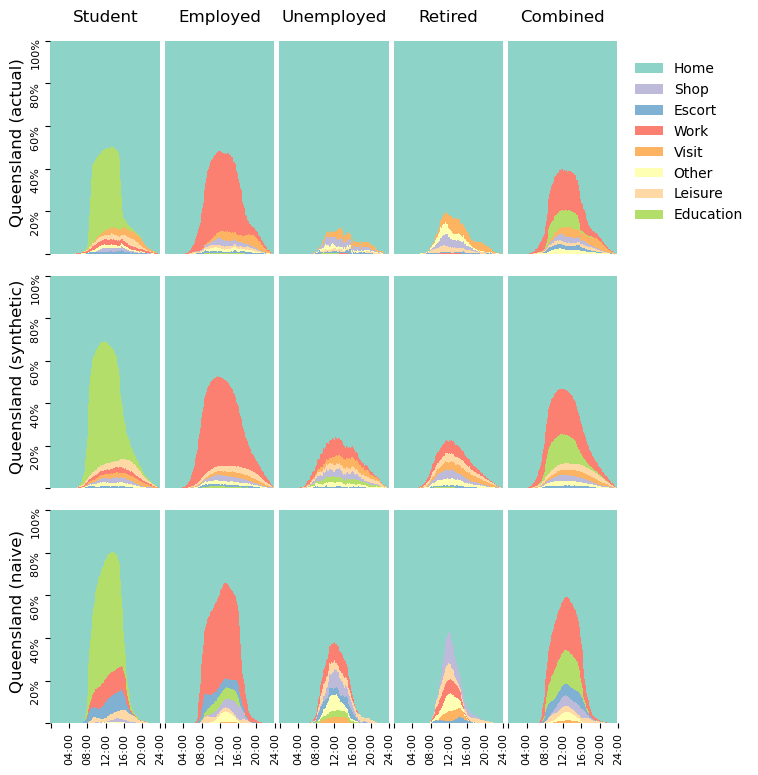

In [ ]:
plot_schedules = {
    "Queensland (actual)": training_schedules["base"],
    "Queensland (synthetic)": schedules["world"],
    "Queensland (naive)": schedules["naive"],
}
plot_attributes = {
    "Queensland (actual)": training_attributes["base"],
    "Queensland (synthetic)": attributes["world"],
    "Queensland (naive)": attributes["naive"],
}
act_order = training_schedules["base"].act.value_counts().index.to_list()
class_map = {n: i for i, n in enumerate(act_order)}
print(f"Class map: {class_map}")

FILTER = ["student", "employed", "unemployed", "retired"]
NAMES = ["Student", "Employed", "Unemployed", "Retired"]

h = len(plot_schedules)
w = len(FILTER)
fig, axes = plt.subplots(
    h, w + 2, figsize=(w * 2.2, h * 3), sharex=False, sharey=False
)

for i, (name, scheds) in enumerate(plot_schedules.items()):

    splits = split_on(scheds, plot_attributes[name], by="employment")

    for j, f in enumerate(FILTER):
        axes[0, j].set_title(NAMES[j], fontsize=12)
        selected = splits[f]
        ax = plot_agg_acts(
            "",
            selected,
            class_map=class_map,
            ax=axes[i, j],
            legend=False,
            color=cmap,
        )
        ax.set_title(None)
        ax.set_ylabel(None)
        ax.set_xlabel(None)
        ax.set_yticks([])
        ax.set_xticks([])

        axes[-1, j].set_xticks(
            [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
            labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
            rotation=90,
            fontsize=8,
        )

    axes[0, -2].set_title("Combined", fontsize=12)
    ax = plot_agg_acts(
        "",
        scheds,
        class_map=class_map,
        ax=axes[i, -2],
        legend=False,
        color=cmap,
    )
    ax.set_title(None)
    ax.set_ylabel(None)
    ax.set_xlabel(None)
    ax.set_yticks([])
    ax.set_xticks([])

    axes[-1, -2].set_xticks(
        [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
        labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
        rotation=90,
        fontsize=8,
    )

    axes[i, 0].set_ylabel(name, fontsize=12)
    axes[i, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    axes[i, 0].set_yticklabels(
        ["", "20% ", "40% ", "60% ", "80% ", "100%"], rotation=90, fontsize=8
    )

    axes[i, -1].axis("off")

elements = [Patch(facecolor=cmap[act], label=act.title()) for act in act_order]
axes[0, -1].axis("off")
axes[0, -1].legend(handles=elements, loc="center left", frameon=False)

plt.subplots_adjust(wspace=0.04, hspace=0.05)

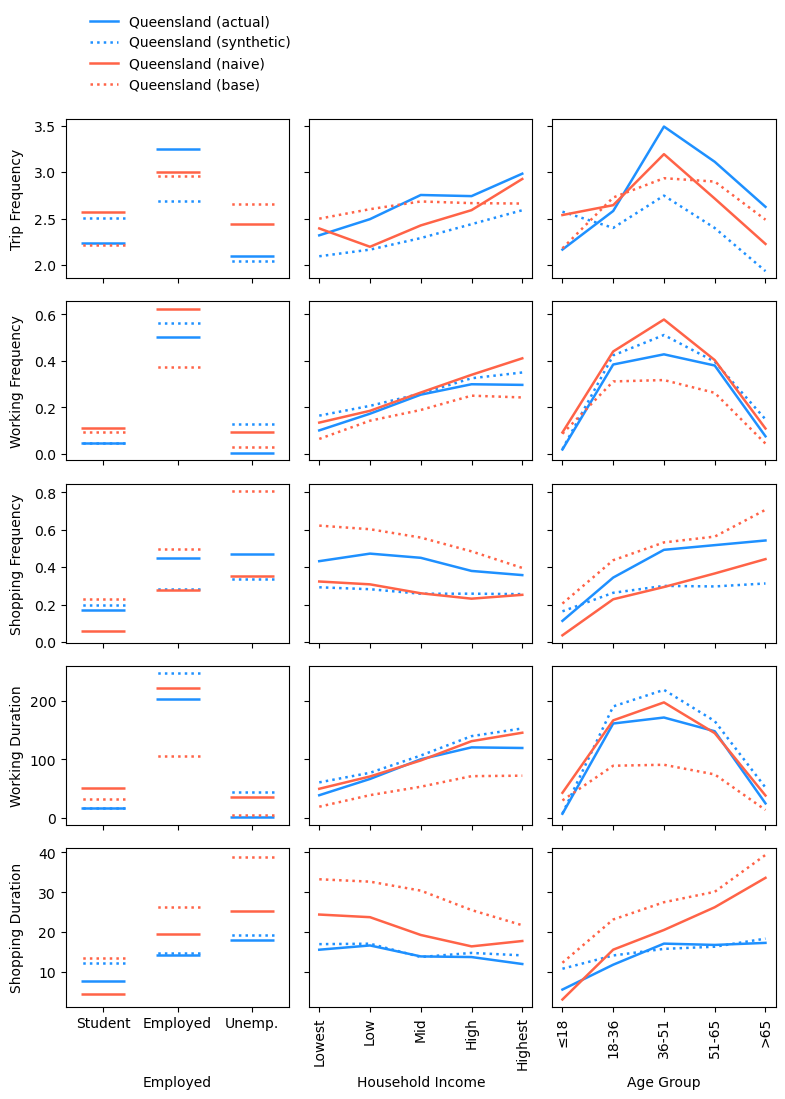

In [ ]:
def duration(schedules, act="work"):
    if "duration" not in schedules.columns:
        durations = schedules.end - schedules.start
    else:
        durations = schedules.duration
    filtered = durations[schedules.act == act]
    n = schedules.pid.nunique()
    return filtered.sum(0) / n


def count_trips(schedules):
    n = schedules.pid.nunique()
    return (len(schedules) - n) / n


def count_acts(schedules, act="work"):
    n = schedules.pid.nunique()
    return len(schedules.loc[schedules.act == act]) / n


def plot_conditionals(
    schedules,
    attributes,
    target_schedules,
    target_attributes,
    figsize=(8, 10),
    target_name="Target",
):
    WORK_STATUS = "employment"
    INCOME = "hh_income"
    AGE = "age"

    work_order = ["student", "employed", "unemployed"]
    work_statuses = ["Student", "Employed", "Unemp."]

    age_order = ["≤18", "18-36", "36-51", "51-65", ">65"]
    ages = age_order

    incomes = ["≤21400", "21400-32526", "32526-47815", "47815-81570", ">81570"]
    colours = [
        "dodgerblue",
        "dodgerblue",
        "tomato",
        "tomato",
        "green",
        "green",
        "pink",
        "pink",
        "orange",
        "orange",
    ]
    styles = ["-", ":", "-", ":", "-", ":", "-", ":", "-", ":"]
    LW = 1.8

    fig, axs = plt.subplots(5, 3, figsize=figsize, sharex="col", sharey="row")

    # ==============================
    # trips employment
    splits = split_on(target_schedules, target_attributes, by=WORK_STATUS)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_trips(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=WORK_STATUS)
        for i, split in splits.items():
            data[n][i] = count_trips(split)

    df = pd.DataFrame(data)
    df = df.loc[work_order]
    ax = axs[0][0]
    # change to bar plot
    for n, col, s in zip(df.columns, colours, styles):
        ax.scatter(
            df.index,
            df[n],
            label=n,
            color=col,
            lw=LW,
            marker="_",
            s=1000,
            linestyle=s,
        )
    ax.set_ylabel("Trip Frequency")
    ax.legend().remove()

    # ==============================
    # trips income
    splits = split_on(target_schedules, target_attributes, by=INCOME)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_trips(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=INCOME)
        for i, split in splits.items():
            data[n][i] = count_trips(split)

    df = pd.DataFrame(data)
    df = df.loc[incomes]
    ax = axs[0][1]
    df.plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()

    # ==================================
    # trips age group
    splits = split_on(target_schedules, target_attributes, by=AGE)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_trips(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=AGE)
        for i, split in splits.items():
            data[n][i] = count_trips(split)

    df = pd.DataFrame(data)
    ax = axs[0][2]
    df.loc[age_order].plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()

    # =================================
    # work employment

    splits = split_on(target_schedules, target_attributes, by=WORK_STATUS)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_acts(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=WORK_STATUS)
        for i, split in splits.items():
            data[n][i] = count_acts(split)

    df = pd.DataFrame(data)
    df = df.loc[work_order]
    ax = axs[1][0]
    for n, col, s in zip(df.columns, colours, styles):
        ax.scatter(
            df.index,
            df[n],
            label=n,
            color=col,
            lw=LW,
            marker="_",
            s=1000,
            linestyle=s,
        )
    ax.set_ylabel("Working Frequency")
    ax.legend().remove()

    # =================================
    # work income

    splits = split_on(target_schedules, target_attributes, by=INCOME)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_acts(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=INCOME)
        for i, split in splits.items():
            data[n][i] = count_acts(split)

    df = pd.DataFrame(data)
    df = df.loc[incomes]
    ax = axs[1][1]
    df.plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()

    # ====================================
    # work age group

    splits = split_on(target_schedules, target_attributes, by=AGE)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_acts(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=AGE)
        for i, split in splits.items():
            data[n][i] = count_acts(split)

    df = pd.DataFrame(data)
    ax = axs[1][2]
    df.loc[age_order].plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()

    # =================================
    # shop employment

    splits = split_on(target_schedules, target_attributes, by=WORK_STATUS)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_acts(split, act="shop")

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=WORK_STATUS)
        for i, split in splits.items():
            data[n][i] = count_acts(split, act="shop")

    df = pd.DataFrame(data)
    df = df.loc[work_order]
    ax = axs[2][0]
    for n, col, s in zip(df.columns, colours, styles):
        ax.scatter(
            df.index,
            df[n],
            label=n,
            color=col,
            lw=LW,
            marker="_",
            s=1000,
            linestyle=s,
        )
    ax.set_ylabel("Shopping Frequency")
    ax.legend().remove()

    # =================================
    # shop income

    splits = split_on(target_schedules, target_attributes, by=INCOME)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_acts(split, act="shop")

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=INCOME)
        for i, split in splits.items():
            data[n][i] = count_acts(split, act="shop")

    df = pd.DataFrame(data)
    df = df.loc[incomes]
    ax = axs[2][1]
    df.plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()

    # ====================================
    # shop age group

    splits = split_on(target_schedules, target_attributes, by=AGE)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = count_acts(split, act="shop")

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=AGE)
        for i, split in splits.items():
            data[n][i] = count_acts(split, act="shop")

    df = pd.DataFrame(data)
    ax = axs[2][2]
    df.loc[age_order].plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()

    # ====================================
    # work employment

    splits = split_on(target_schedules, target_attributes, by=WORK_STATUS)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = duration(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=WORK_STATUS)
        for i, split in splits.items():
            data[n][i] = duration(split)

    df = pd.DataFrame(data)
    df = df.loc[work_order]
    ax = axs[3][0]
    for n, col, s in zip(df.columns, colours, styles):
        ax.scatter(
            df.index,
            df[n],
            label=n,
            color=col,
            lw=LW,
            marker="_",
            s=1000,
            linestyle=s,
        )
    ax.legend().remove()
    ax.set_ylabel("Working Duration")

    # ====================================
    # work income

    splits = split_on(target_schedules, target_attributes, by=INCOME)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = duration(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=INCOME)
        for i, split in splits.items():
            data[n][i] = duration(split)

    df = pd.DataFrame(data)
    df = df.loc[incomes]
    ax = axs[3][1]
    df.plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()

    # ====================================
    # work age group

    splits = split_on(target_schedules, target_attributes, by=AGE)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = duration(split)

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=AGE)
        for i, split in splits.items():
            data[n][i] = duration(split)

    df = pd.DataFrame(data)
    ax = axs[3][2]
    df.loc[age_order].plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()

    # ====================================
    # shop employment

    splits = split_on(target_schedules, target_attributes, by=WORK_STATUS)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = duration(split, act="shop")

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=WORK_STATUS)
        for i, split in splits.items():
            data[n][i] = duration(split, act="shop")

    df = pd.DataFrame(data)
    df = df.loc[work_order]
    ax = axs[4][0]
    for n, col, s in zip(df.columns, colours, styles):
        ax.scatter(
            df.index,
            df[n],
            label=n,
            color=col,
            lw=LW,
            marker="_",
            s=1000,
            linestyle=s,
        )

    ax.legend().remove()
    ax.set_xlim(-0.5, 2.5)

    ax.set_ylabel("Shopping Duration")
    ax.set_xlabel("Employed")
    ax.set_xticks(list(range(len(work_order))), work_statuses, rotation=0)

    # ====================================
    # shop income

    splits = split_on(target_schedules, target_attributes, by=INCOME)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = duration(split, act="shop")

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=INCOME)
        for i, split in splits.items():
            data[n][i] = duration(split, act="shop")

    df = pd.DataFrame(data)
    df = df.loc[incomes]
    ax = axs[4][1]
    df.plot(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()
    ax.set_xlabel("Household Income")
    ax.set_xticks(
        [0, 1, 2, 3, 4],
        ["Lowest", "Low", "Mid", "High", "Highest"],
        rotation=90,
    )

    # ====================================
    # shop age group

    splits = split_on(target_schedules, target_attributes, by=AGE)
    data = {target_name: {}}
    for i, split in splits.items():
        data[target_name][i] = duration(split, act="shop")

    for n, scheds in schedules.items():
        data[n] = {}
        atts = attributes[n]
        splits = split_on(scheds, atts, by=AGE)
        for i, split in splits.items():
            data[n][i] = duration(split, act="shop")

    df = pd.DataFrame(data)
    ax = axs[4][2]
    df.loc[age_order].plot.line(ax=ax, color=colours, style=styles, lw=LW)
    ax.legend().remove()
    ax.set_xlabel("Age Group")
    ax.set_xticks(range(len(ages)), ages, rotation=90)

    # for ax in axs.flat:
    #     ax.grid(visible=True, which="major", axis="x", color="grey", linestyle="-")

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        frameon=False,
        fontsize=10,
        bbox_to_anchor=(0.25, 1),
    )

    fig.align_ylabels(axs[:, 0])
    fig.align_xlabels(axs[-1, :])

    fig.tight_layout()


plot_conditionals(
    {
        # "Queensland": schedules["base"],
        # "Victoria (actual)": training_schedules["australia"],
        # "Victoria": schedules["australia"],
        # "World (actual)": training_schedules["western"],
        "Queensland (synthetic)": schedules["world"],
        "Queensland (naive)": schedules["naive"],
        "Queensland (base)": schedules["base"],
    },
    {
        # "Queensland": attributes["base"],
        # "Victoria (actual)": training_attributes["australia"],
        # "Victoria": attributes["australia"],
        # "World (actual)": training_attributes["western"],
        "Queensland (synthetic)": attributes["world"],
        "Queensland (naive)": attributes["naive"],
        "Queensland (base)": attributes["base"],
    },
    training_schedules["base"],
    training_attributes["base"],
    target_name="Queensland (actual)",
)